In [26]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import copy

from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from statsmodels.tsa.stattools import acf

from utils import (
    set_seed,
    create_windows,
    Linear,
    DLinear,
    NLinear,
    train_model,
    evaluate_model,
    train_one_epoch,
    validate
)

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

set_seed(42)

In [ ]:
# URL raw file từ GitHub
url = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

df = pd.read_csv(url)

df.to_csv("ETTh1.csv", index=False)

Đã tải thành công file ETTh1.csv!


In [4]:
data_path = PROJECT_ROOT / "data" / "ETTh1.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset shape: (17420, 8)
Columns: ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


In [5]:
print(df.isnull().sum())
print(df.dtypes)

date    0
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64
date        str
HUFL    float64
HULL    float64
MUFL    float64
MULL    float64
LUFL    float64
LULL    float64
OT      float64
dtype: object


In [ ]:
df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date").reset_index(drop=True)

assert df["date"].is_monotonic_increasing #kiểm tra xem cột date có tăng dần hay không
assert df["OT"].notna().all() # kiểm tra xem cột OT có giá trị null hay không

print("Start:", df["date"].min())
print("End:", df["date"].max())

Start: 2016-07-01 00:00:00
End: 2018-06-26 19:00:00


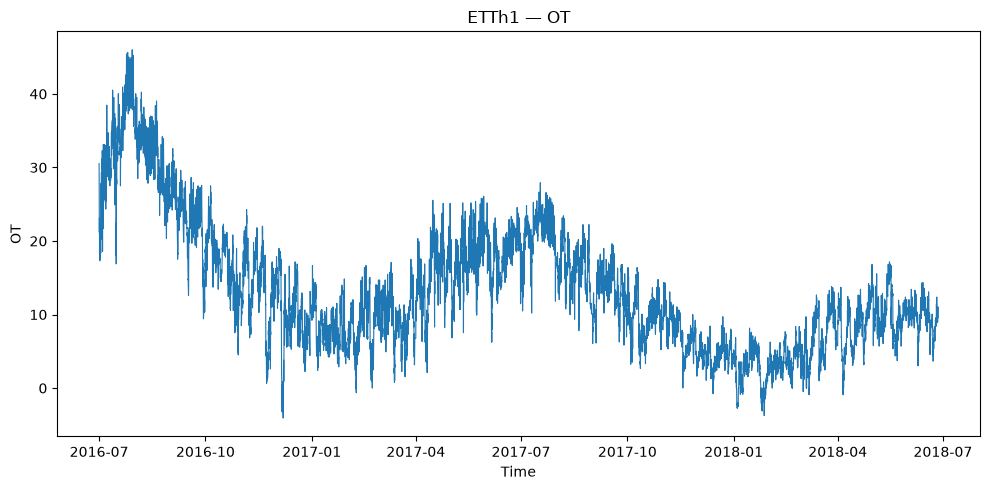

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    df["date"],
    df["OT"],
    linewidth=0.8
)

ax.set_title("ETTh1 — OT")
ax.set_xlabel("Time")
ax.set_ylabel("OT")

plt.tight_layout()
plt.show()

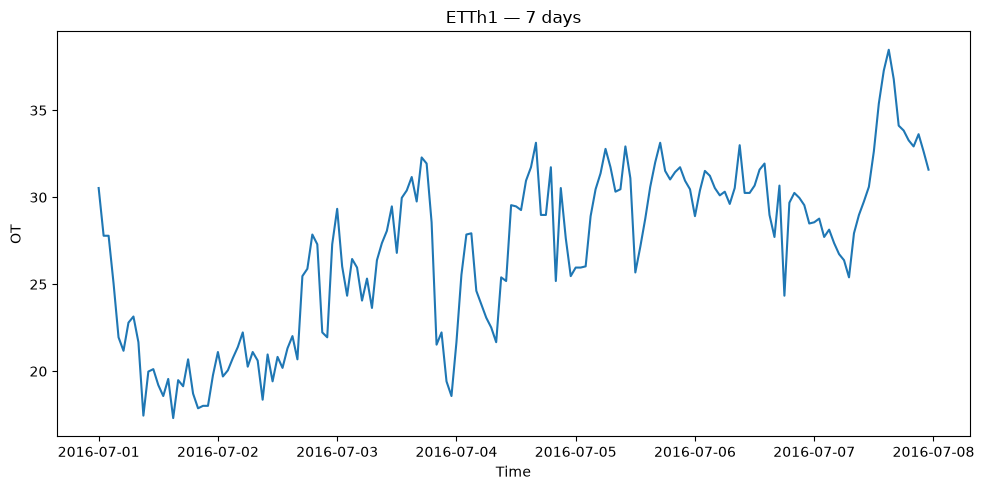

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    df["date"].iloc[:168], # 7 ngày * 24h = 168 giờ
    df["OT"].iloc[:168]
)

ax.set_title("ETTh1 — 7 days")
ax.set_xlabel("Time")
ax.set_ylabel("OT")

plt.tight_layout()
plt.show()

**Nhận xét:**
- Dữ liệu có tính lặp lại theo ngày nhưng nó không thực sự rõ rệt
- Nhiễu ở tần số cao

=> Vì đây là dữ liệu thực tế nên em chưa biết được tính chu kì của nó diễn ra như thế nào, vậy nên em sử dụng pp tính chu kì bằng ACF 
"https://arxiv.org/abs/2106.13008"

In [9]:
values = df["OT"].to_numpy(dtype=np.float32)

train_end = 12 * 30 * 24
val_end = train_end + 4 * 30 * 24

assert len(values) >= val_end + 4 * 30 * 24

train_raw = values[:train_end]
val_raw = values[train_end:val_end]
test_raw = values[val_end:val_end + 4 * 30 * 24]

print(len(train_raw), len(val_raw), len(test_raw))

8640 2880 2880


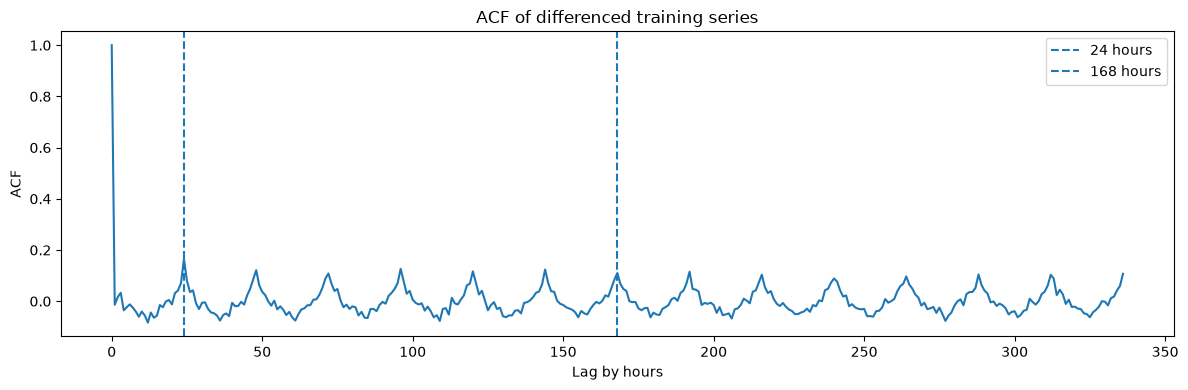

In [ ]:
train_diff = np.diff(train_raw) # tính sai phân lùi bậc 1 delta_xt = xt - xt-1

acf_values = acf(
    train_diff,
    nlags=24 * 14,
    fft=True
)

lags = np.arange(len(acf_values))

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(lags, acf_values)

ax.axvline(24, linestyle="--", label="24 hours")
ax.axvline(168, linestyle="--", label="168 hours")

ax.set_xlabel("Lag by hours")
ax.set_ylabel("ACF")
ax.set_title("ACF of differenced training series")

ax.legend()
plt.tight_layout()
plt.show()

**Nhận xét:**
- Đỉnh nhọn lặp lại đúng 24 giờ, đường line 24 giờ khớp hoàn toàn với đỉnh cục bộ đầu tiên.
- Đường nét đứt 168 giờ nhô cao tương ứng như đỉnh 24 giờ cho thấy có cả tính chu kì lặp lại 7 ngày

=> chuyển sang miền tần số bằng FFT sẽ giúp tìm và phân tích chu kì tốt hơn việc chỉ phân tích P theo time truyền thống
"https://arxiv.org/abs/2210.02186"


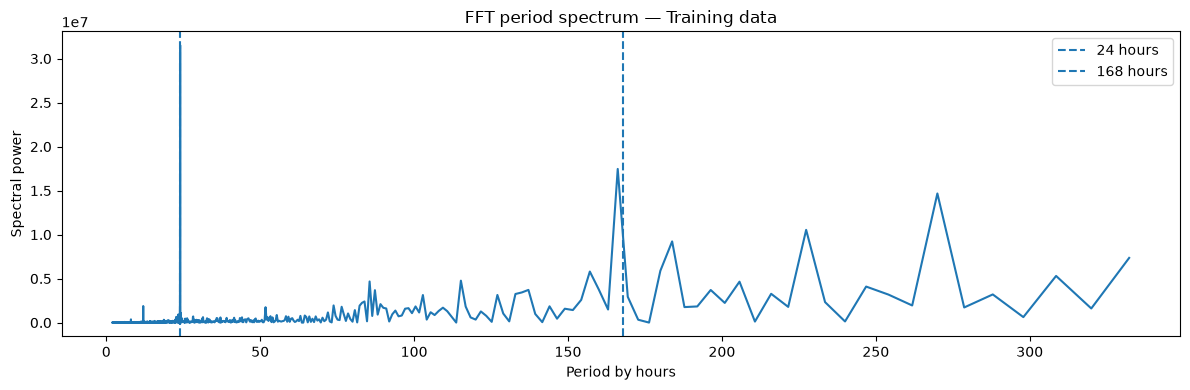

In [13]:
signal = train_raw - np.mean(train_raw)

frequencies = np.fft.rfftfreq(len(signal), d=1.0)

spectrum = np.abs(np.fft.rfft(signal))

valid = frequencies > 0

periods = 1 / frequencies[valid]
power = spectrum[valid] ** 2

mask = (periods >= 2) & (periods <= 336)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    periods[mask],
    power[mask]
)

ax.axvline(24, linestyle="--", label="24 hours")
ax.axvline(168, linestyle="--", label="168 hours")

ax.set_xlabel("Period by hours")
ax.set_ylabel("Spectral power")
ax.set_title("FFT period spectrum — Training data")

ax.legend()
plt.tight_layout()
plt.show()

**Nhận xét:**
- Dựa vào 2 biểu đồ thực nghiệm thì em có thể lựa chọn P = 24 giờ cho chu kì mùa vụ chủ đạo cho bộ dữ liệu này
- Tại mốc P = 24 trên biểu đồ FFT nhô cao hẳn, áp đảo so với các tần số khác
- Tại P = 168 thì tần số của nó chỉ bằng 1/2 so với đỉnh P = 24

=> trong kiến trúc của Dlinear thì sử dụng bộ lọc MA mục tiêu để triệt tiêu đi tính mùa vụ tần số cao nhất để thu được trend mượt nhất

In [14]:
# Scaler data
scaler = StandardScaler()

scaler.fit(train_raw.reshape(-1, 1))

scaled_values = scaler.transform(values.reshape(-1, 1)).reshape(-1).astype(np.float32)

In [ ]:
def make_split_windows(
    series,
    lookback,
    horizon,
    target_start,
    target_end
):
    X, y = [], []

    for target_idx in range(target_start, target_end - horizon + 1):

        input_start = target_idx - lookback

        if input_start < 0: # nếu L không đủ bước ở phía trước, vòng lặp sẽ bỏ qua để tránh lỗi truy cập idx âm hoặc null
            continue

        X.append(series[input_start:target_idx])

        y.append(series[target_idx:target_idx + horizon])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32)
    )

In [18]:
# dataloader

def prepare_real_data(
    series,
    lookback,
    horizon,
    train_end,
    val_end,
    test_end,
    batch_size=32,
    seed=42
):
    X_train, y_train = make_split_windows(series, lookback, horizon, lookback, train_end)

    X_val, y_val = make_split_windows(series, lookback, horizon, train_end, val_end)

    X_test, y_test = make_split_windows(series, lookback, horizon, val_end, test_end)

    def to_loader(X, y, shuffle=False):
        dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))

        generator = torch.Generator().manual_seed(seed)

        return DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=shuffle,
            generator=generator
        )

    return (
        to_loader(X_train, y_train, True),
        to_loader(X_val, y_val),
        to_loader(X_test, y_test)
    )

In [19]:
P = 24
L = 96
T = 24

train_loader, val_loader, test_loader = prepare_real_data(
    series=scaled_values,
    lookback=L,
    horizon=T,
    train_end=train_end,
    val_end=val_end,
    test_end=val_end + len(test_raw),
    batch_size=32
)

X_batch, y_batch = next(iter(train_loader))

print("Input:", X_batch.shape)
print("Target:", y_batch.shape)

Input: torch.Size([32, 96])
Target: torch.Size([32, 24])


In [ ]:
# train Dlinear
set_seed(42)

model = DLinear(
    lookback=L,
    horizon=T,
    kernel_size=5
)

train_losses, val_losses = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    learning_rate=1e-3
)

mse, mae, predictions, targets = evaluate_model(model=model, test_loader=test_loader)

print("Test MSE:", mse)
print("Test MAE:", mae)
print("Predictions:", predictions.shape)
print("Targets:", targets.shape)

Epoch   1/10 | Train MSE: 0.161498 | Val MSE: 0.061787
Epoch  10/10 | Train MSE: 0.082568 | Val MSE: 0.051325
Test MSE: 0.029914362356066704
Test MAE: 0.12846292555332184
Predictions: (2857, 24)
Targets: (2857, 24)


In [21]:
real_configs = [
    (1, 1),
    (4, 1),
    (1, 4),
    (4, 4)
]

In [22]:
models = [
    "Linear",
    "DLinear",
    "NLinear"
]

In [ ]:
# hàm training có best checkpoint
def train_best_model(
    model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    device=None,
    verbose=False
):
    if device is None:
        device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

    model = model.to(device)

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    val_losses = []

    best_val_mse = float("inf")
    best_epoch = 0
    best_state = None

    for epoch in range(epochs):

        train_loss = train_one_epoch(
            model=model,
            train_loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            device=device
        )

        val_loss = validate(
            model=model,
            val_loader=val_loader,
            criterion=criterion,
            device=device
        )

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_val_mse:
            best_val_mse = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

        if verbose and (
            epoch == 0
            or (epoch + 1) % 10 == 0
            or epoch + 1 == epochs
        ):
            print(
                f"Epoch {epoch+1}/{epochs} | "
                f"Train={train_loss:.6f} | "
                f"Val={val_loss:.6f}"
            )

    model.load_state_dict(best_state)

    return model, {
        "best_epoch": best_epoch,
        "best_val_mse": best_val_mse,
        "train_losses": train_losses,
        "val_losses": val_losses
    }

In [27]:
set_seed(42)

train_loader, val_loader, test_loader = prepare_real_data(
    series=scaled_values,
    lookback=96,
    horizon=24,
    train_end=train_end,
    val_end=val_end,
    test_end=val_end + len(test_raw),
    batch_size=32,
    seed=42
)

model = DLinear(
    lookback=96,
    horizon=24,
    kernel_size=5
)

model, history = train_best_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    verbose=True
)

print("Best epoch:", history["best_epoch"])
print("Best validation MSE:", history["best_val_mse"])

Epoch 1/10 | Train=0.159838 | Val=0.061969
Epoch 10/10 | Train=0.082746 | Val=0.051385
Best epoch: 8
Best validation MSE: 0.05137399009516607


In [28]:
def run_real_experiment(
    model_name,
    period,
    lookback,
    horizon,
    epochs=50,
    learning_rate=1e-3,
    kernel_size=5,
    seed=42
):
    set_seed(seed)

    train_loader, val_loader, test_loader = prepare_real_data(
        series=scaled_values,
        lookback=lookback,
        horizon=horizon,
        train_end=train_end,
        val_end=val_end,
        test_end=val_end + len(test_raw),
        batch_size=32,
        seed=seed
    )

    if model_name == "Linear":
        model = Linear(lookback, horizon)

    elif model_name == "DLinear":
        model = DLinear(
            lookback,
            horizon,
            kernel_size=kernel_size
        )

    elif model_name == "NLinear":
        model = NLinear(lookback, horizon)

    else:
        raise ValueError(f"Unknown model: {model_name}")

    model, history = train_best_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=epochs,
        learning_rate=learning_rate
    )

    mse, mae, predictions, targets = evaluate_model(
        model=model,
        test_loader=test_loader
    )

    return {
        "Dataset": "ETTh1",
        "Model": model_name,
        "P": period,
        "L": lookback,
        "T": horizon,
        "L/P": lookback / period,
        "T/P": horizon / period,
        "MSE": mse,
        "MAE": mae,
        "Best_epoch": history["best_epoch"],
        "Best_val_MSE": history["best_val_mse"],
        "Seed": seed
    }

In [29]:
# test model
models = ["Linear", "DLinear", "NLinear"]

sanity_results = []

for model_name in models:

    print(f"\nTesting {model_name}")

    result = run_real_experiment(
        model_name=model_name,
        period=24,
        lookback=96,
        horizon=24,
        epochs=10,
        seed=42
    )

    sanity_results.append(result)

sanity_df = pd.DataFrame(sanity_results)

sanity_df[
    ["Model", "MSE", "MAE", "Best_epoch"]
]


Testing Linear

Testing DLinear

Testing NLinear


,Model,MSE,MAE,Best_epoch
0,Linear,0.033829,0.138281,10
1,DLinear,0.027282,0.125207,8
2,NLinear,0.026658,0.124326,8


In [30]:
P_REAL = 24

real_configs = [
    (1, 1),
    (4, 1),
    (1, 4),
    (4, 4)
]

models = ["Linear", "DLinear", "NLinear"]

real_results = []

for context_ratio, forecast_ratio in real_configs:

    L = int(P_REAL * context_ratio)
    T = int(P_REAL * forecast_ratio)

    for model_name in models:

        print(
            f"Model={model_name} | "
            f"L/P={context_ratio} | "
            f"T/P={forecast_ratio}"
        )

        result = run_real_experiment(
            model_name=model_name,
            period=P_REAL,
            lookback=L,
            horizon=T,
            epochs=50,
            seed=42
        )

        real_results.append(result)

Model=Linear | L/P=1 | T/P=1
Model=DLinear | L/P=1 | T/P=1
Model=NLinear | L/P=1 | T/P=1
Model=Linear | L/P=4 | T/P=1
Model=DLinear | L/P=4 | T/P=1
Model=NLinear | L/P=4 | T/P=1
Model=Linear | L/P=1 | T/P=4
Model=DLinear | L/P=1 | T/P=4
Model=NLinear | L/P=1 | T/P=4
Model=Linear | L/P=4 | T/P=4
Model=DLinear | L/P=4 | T/P=4
Model=NLinear | L/P=4 | T/P=4


In [31]:
real_df = pd.DataFrame(real_results)

real_df[
    [
        "Model",
        "L/P",
        "T/P",
        "MSE",
        "MAE",
        "Best_epoch"
    ]
]

,Model,L/P,T/P,MSE,MAE,Best_epoch
0,Linear,1.0,1.0,0.037560,0.145936,38
1,DLinear,1.0,1.0,0.037045,0.142327,22
2,NLinear,1.0,1.0,0.029739,0.129464,42
3,Linear,4.0,1.0,0.028956,0.126922,45
4,DLinear,4.0,1.0,0.031797,0.132698,47
5,NLinear,4.0,1.0,0.026520,0.123723,31
6,Linear,1.0,4.0,0.083629,0.216907,48
7,DLinear,1.0,4.0,0.103462,0.245253,17
8,NLinear,1.0,4.0,0.059715,0.189539,50
9,Linear,4.0,4.0,0.063513,0.187831,50


In [32]:
real_df.to_csv(RESULTS_DIR / "real_world_results.csv", index=False)

In [33]:
real_mse_table = real_df.pivot(
    index=["L/P", "T/P"],
    columns="Model",
    values="MSE"
)

real_mse_table

Model     DLinear    Linear   NLinear
L/P T/P                              
1.0 1.0  0.037045  0.037560  0.029739
    4.0  0.103462  0.083629  0.059715
4.0 1.0  0.031797  0.028956  0.026520
    4.0  0.066339  0.063513  0.055316

In [34]:
real_mse_table["DLinear_Gain_%"] = (
    (
        real_mse_table["Linear"]
        - real_mse_table["DLinear"]
    )
    / real_mse_table["Linear"]
) * 100

real_mse_table["Best_Model"] = (
    real_mse_table[
        ["Linear", "DLinear", "NLinear"]
    ].idxmin(axis=1)
)

real_mse_table

Model     DLinear    Linear   NLinear  DLinear_Gain_% Best_Model
L/P T/P                                                         
1.0 1.0  0.037045  0.037560  0.029739        1.371087    NLinear
    4.0  0.103462  0.083629  0.059715      -23.715290    NLinear
4.0 1.0  0.031797  0.028956  0.026520       -9.811136    NLinear
    4.0  0.066339  0.063513  0.055316       -4.450405    NLinear

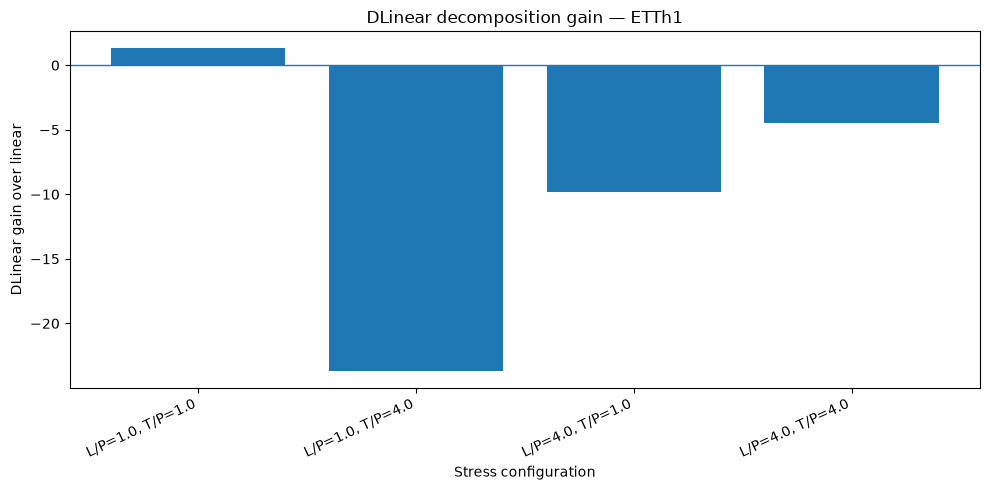

In [35]:
real_gain_df = real_mse_table.reset_index()

real_gain_df["Configuration"] = (
    "L/P=" + real_gain_df["L/P"].astype(str)
    + ", T/P=" + real_gain_df["T/P"].astype(str)
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    real_gain_df["Configuration"],
    real_gain_df["DLinear_Gain_%"]
)

ax.axhline(0, linewidth=1)

ax.set_xlabel("Stress configuration")
ax.set_ylabel("DLinear gain over linear")
ax.set_title("DLinear decomposition gain — ETTh1")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "real_world_dlinear_gain.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Nhận xét:**
- Dlinear hạot động tốt hơn 1 chút so với Linear khi độ dài T = 24 (L = 24, H = 24)
- 1.0:4.0 thì Dlinear hoạt động kém hơn Linear 1 cách rõ rệt, khi lịch sử quá ngắn nhưng phải dự báo tương lai dài thì cơ chế decomposition bị thiếu thông tin quá khứ để bóc tách trend 1 cách chính xác (L = 24, H = 96)
- 4.0:1.0 Linear vẫn tốt hơn Dlinear 
- 4.0:4.0 cũng thế

=> Linear đơn giản vẫn vượt trội hơn hoặc tương đương với Dlinear trong phần lớn các cấu hình cho tầm nhìn xa

=> Dlinear với bộ dữ liệu này đang cho thấy ưu thế với cửa sổ dự báo ngắn

In [36]:
synthetic_df = pd.read_csv(RESULTS_DIR / "model_comparison.csv")

synthetic_mse = synthetic_df.pivot_table(
    index=["L/P", "T/P"],
    columns="Model",
    values="MSE"
)

synthetic_mse["Synthetic_Gain_%"] = (
    (
        synthetic_mse["Linear"]
        - synthetic_mse["DLinear"]
    )
    / synthetic_mse["Linear"]
) * 100

comparison_summary = pd.DataFrame({
    "Synthetic_Gain_%": synthetic_mse["Synthetic_Gain_%"],
    "Real_Gain_%": real_mse_table["DLinear_Gain_%"]
})

comparison_summary = comparison_summary.dropna()

comparison_summary

Synthetic_Gain_%  Real_Gain_%
L/P T/P                               
1.0 1.0         -6.678536     1.371087
    4.0         -4.335989   -23.715290
4.0 1.0       -792.133272    -9.811136
    4.0       -306.242917    -4.450405

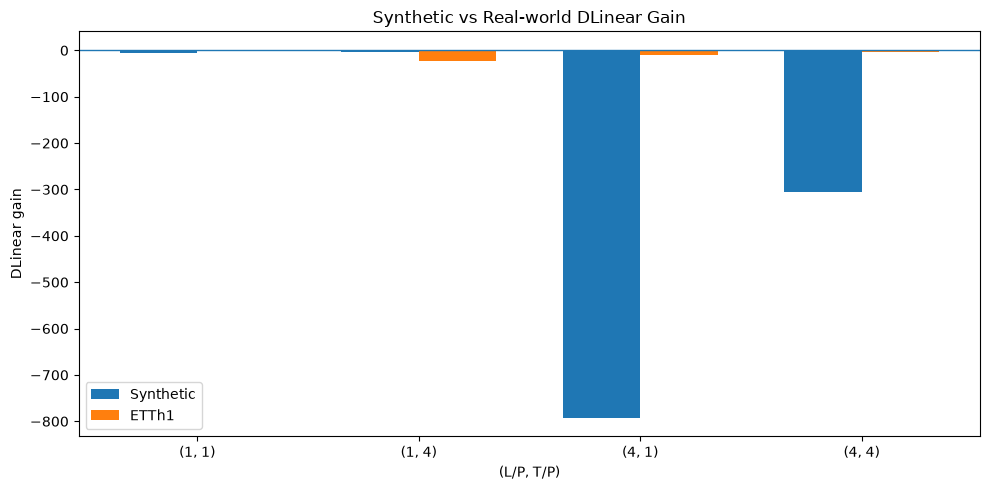

In [38]:
comparison_plot = comparison_summary.reset_index()

labels = [
    f"({row['L/P']:g}, {row['T/P']:g})"
    for _, row in comparison_plot.iterrows()
]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - width / 2,
    comparison_plot["Synthetic_Gain_%"],
    width,
    label="Synthetic"
)

ax.bar(
    x + width / 2,
    comparison_plot["Real_Gain_%"],
    width,
    label="ETTh1"
)

ax.axhline(0, linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.set_xlabel("(L/P, T/P)")
ax.set_ylabel("DLinear gain")
ax.set_title("Synthetic vs Real-world DLinear Gain")

ax.legend()

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "synthetic_vs_real_gain.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()